# Обещали доставить

SQL, качество сервиса и честная проверка модели риска опоздания. Данные Olist, версия 2, CC BY-NC-SA 4.0. Пересборка: **python run.py**. Ноутбук читает результаты и независимо проверяет ключевые расчёты.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
ROOT=Path.cwd()
if not (ROOT/'run.py').exists():
    ROOT=ROOT.parent
R=json.loads((ROOT/'reports/results.json').read_text(encoding='utf-8'))
print('Заказов в источнике:',R['quality']['source_rows']['orders'])
print('Строк в SQL-витрине:',R['quality']['mart_rows'])
print('Уникальных заказов:',R['quality']['mart_unique_orders'])
print('Суммы после JOIN:',R['quality']['reconciliation'])

Заказов в источнике: 99441
Строк в SQL-витрине: 99441
Уникальных заказов: 99441
Суммы после JOIN: {'items_value': 13591643.700000003, 'freight_value': 2251909.54, 'paid_value': 16008872.12}


## 1. Бизнес-вопрос и правильный знаменатель
Где нарушаются обещания и можно ли заранее выделить риск? Сроки оцениваем среди доставленных заказов с валидными датами. Отмены считаем отдельно по всем заказам. День обещания включён в своевременную доставку.

In [2]:
o=R['overview']
print('Основная когорта:',o['orders'])
print('Доставлено с валидными датами:',o['delivered'])
print('Опоздали:',o['late'])
print('Доля опозданий:',round(o['late']/o['delivered'],6))
print('Доля отмен:',round(o['canceled']/o['orders'],6))
assert np.isclose(o['late']/o['delivered'],o['late_rate'])

Основная когорта: 99092
Доставлено с валидными датами: 96203
Опоздали: 6531
Доля опозданий: 0.067888
Доля отмен: 0.005853


## 2. SQL без размножения денег
Один заказ может иметь несколько товаров, оплат и отзывов. Сначала сворачиваем каждую таблицу до заказа, затем соединяем. Файл sql/01_order_mart.sql содержит CTE, оконные функции выбора основного продавца, категории и последнего отзыва.

In [3]:
import duckdb
con=duckdb.connect(str(ROOT/'data/processed/analytics.duckdb'),read_only=True)
checks=con.sql('''
    SELECT COUNT(*) AS rows,COUNT(DISTINCT order_id) AS unique_orders,
           SUM(items_value) AS items_value,SUM(paid_value) AS paid_value
    FROM order_mart
''').df()
checks.columns=['Строк','Уникальных заказов','Стоимость товаров, BRL','Оплачено, BRL']
print(checks.to_string(index=False))
con.close()
assert checks.iloc[0,0]==checks.iloc[0,1]

 Строк  Уникальных заказов  Стоимость товаров, BRL  Оплачено, BRL
 99441               99441            1.359164e+07   1.600887e+07


## 3. Отзывы: связь не равна причине
Сравниваем последний ответ, оставленный не раньше доставки. Отбор по отзывам и различия заказов ограничивают вывод. Причинный ущерб или прибыль не рассчитываем.

In [4]:
reviews=pd.read_csv(ROOT/'reports/tables/review_comparison.csv')
print(reviews.rename(columns={'group':'Доставка','n':'Отзывов','low_rate':'Доля оценок 1–2',
    'mean_score':'Средняя оценка'})[['Доставка','Отзывов','Доля оценок 1–2','Средняя оценка']].to_string(index=False))
print('Повторных записей отзывов:',R['quality']['extra_review_records'])
print('Ответов до доставки исключено:',R['quality']['reviews_before_delivery'])

    Доставка  Отзывов  Доля оценок 1–2  Средняя оценка
      В срок    89005         0.092321        4.291793
С опозданием     1907         0.194546        3.719455
Повторных записей отзывов: 551
Ответов до доставки исключено: 4648


## 4. Проверка по времени и доступность признаков
Обучение — 2017 год, валидация — январь–февраль 2018, тест — май–июнь. Промежутки нужны для дозревания исходов. Перед тестом финально обучаемся на доступном прошлом. Обещание, корзина, назначенный продавец и каталог предполагаются известными при покупке; истории их изменений в наборе нет.

In [5]:
splits=pd.read_csv(ROOT/'data/processed/model_splits.csv',
    parse_dates=['order_purchase_timestamp','order_delivered_customer_date'])
for name,label in [('train','Обучение подбора'),('validation','Валидация'),
                   ('final_fit','Финальное обучение'),('test','Тест')]:
    g=splits[splits.split==name]
    print(label,len(g),'заказов; покупки',g.order_purchase_timestamp.min(),'—',g.order_purchase_timestamp.max())
fit=splits[splits.split=='final_fit']
test=splits[splits.split=='test']
assert not set(fit.order_id)&set(test.order_id)
assert fit.order_delivered_customer_date.max()<test.order_purchase_timestamp.min()
print('Обучение не использует ещё неизвестные тестовые исходы: да')
print('Модель:',R['primary']['label'])
print('Тест использован для выбора:',R['selection']['test_used_for_selection'])

Обучение подбора 30621 заказов; покупки 2017-01-05 11:56:06 — 2017-10-31 23:50:58
Валидация 13587 заказов; покупки 2018-01-01 02:48:41 — 2018-02-28 23:57:55
Финальное обучение 57011 заказов; покупки 2017-01-05 11:56:06 — 2018-02-28 23:57:55
Тест 12845 заказов; покупки 2018-05-01 00:02:11 — 2018-06-30 23:59:49
Обучение не использует ещё неизвестные тестовые исходы: да
Модель: Логистическая регрессия
Тест использован для выбора: False


## 5. Модель и простая альтернатива
Кандидат выбирается по average precision на валидации. Сравниваем с постоянным риском и правилом короткого обещанного срока. Последнее задаёт ранжирование, но не вероятность. Поэтому Brier для правила не интерпретируем.

In [6]:
m=pd.read_csv(ROOT/'reports/tables/test_model_metrics.csv')
print(m[['label','average_precision','roc_auc','precision_at_budget','recall_at_budget','brier']].rename(columns={
    'label':'Стратегия','average_precision':'AP','roc_auc':'ROC-AUC','precision_at_budget':'Точность при 20%',
    'recall_at_budget':'Полнота при 20%','brier':'Brier'}).to_string(index=False))

              Стратегия       AP  ROC-AUC  Точность при 20%  Полнота при 20%    Brier
        Постоянный риск 0.040016 0.500000          0.040016         0.200000 0.039072
Короткий обещанный срок 0.056658 0.649387          0.056831         0.284047      NaN
Логистическая регрессия 0.101382 0.743042          0.096536         0.482490 0.037847


## 6. Независимый пересчёт бюджета
На тесте фиксированный бюджет 20%. При равных оценках порядок задаётся order_id. Проверяем расчёт напрямую, без функции расчёта метрик из проекта.

In [7]:
h=pd.read_csv(ROOT/'data/processed/test_predictions.csv')
k=int(np.floor(.2*len(h)))
selected=np.lexsort((h.order_id.to_numpy(),-h.probability.to_numpy()))[:k]
precision=h.iloc[selected].late.mean()
recall=h.iloc[selected].late.sum()/h.late.sum()
print('Всего тестовых заказов:',len(h),'В приоритете:',k)
print('Опозданий в приоритете:',int(h.iloc[selected].late.sum()))
print('Точность:',round(precision,5),'Полнота:',round(recall,5))
assert np.isclose(precision,R['primary']['precision_at_budget'])
assert np.isclose(recall,R['primary']['recall_at_budget'])
print('Сохранённые результаты воспроизведены: да')

Всего тестовых заказов: 12845 В приоритете: 2569
Опозданий в приоритете: 248
Точность: 0.09654 Полнота: 0.48249
Сохранённые результаты воспроизведены: да


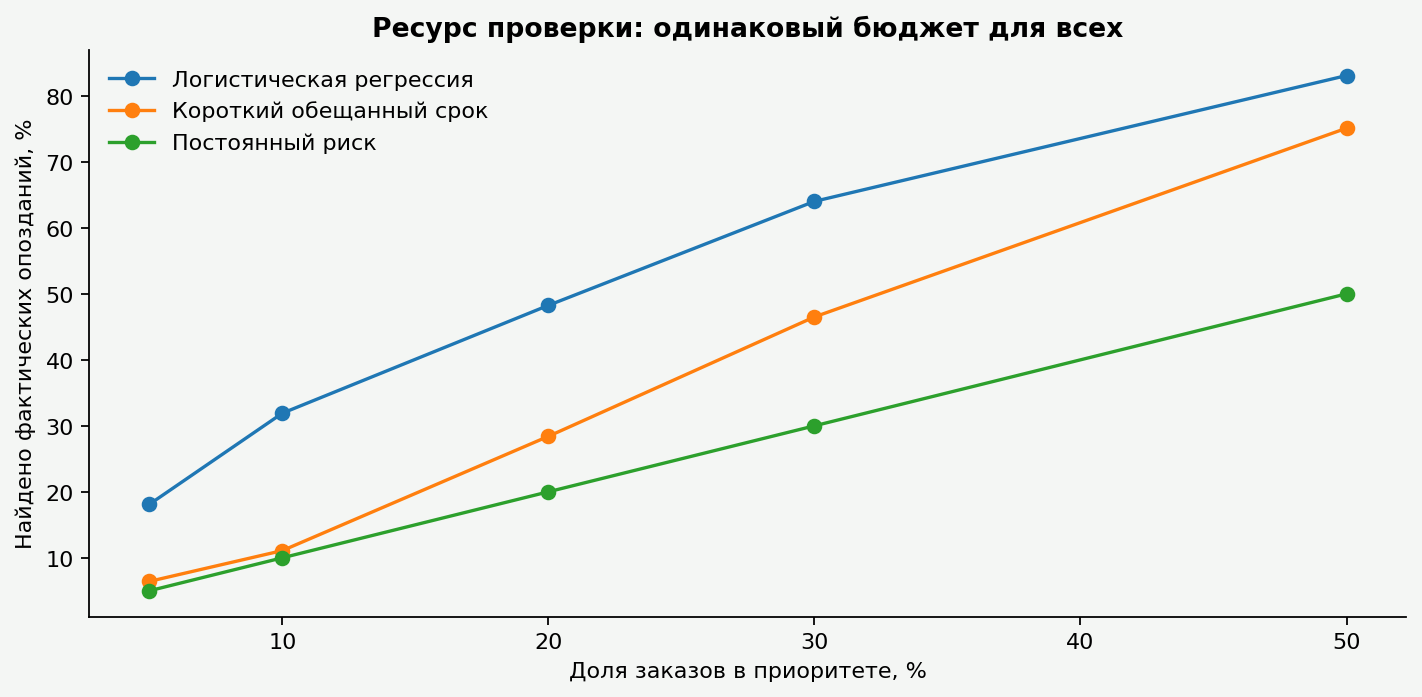

In [8]:
# График из воспроизводимого анализа: python run.py

## 7. Что проверить перед внедрением
Модель оценена условно на доставленных заказах. Нужна полная новая когорта, подтверждение доступности полей в момент покупки, контроль калибровки и изменения частоты опозданий. Пользу реального вмешательства оцениваем отдельным экспериментом. Текущий bootstrap не учитывает переобучение и временную зависимость заказов продавца.

In [9]:
print('Доля опозданий по выборкам:')
for name in ['train','validation','test']:
    print(name,round(R['split_late'][name]/R['split_counts'][name]*100,2),'%')
print('Разница полноты модели и правила:',R['comparison_vs_rule'])
print('Дашборд: reports/dashboard.html')
print('Полный отчёт: reports/REPORT_RU.md')

Доля опозданий по выборкам:
train 3.7 %
validation 9.51 %
test 4.0 %
Разница полноты модели и правила: {'recall_difference': 0.19844357976653698, 'repeats': 300, 'low': 0.14093421459492889, 'high': 0.2638640488247519}
Дашборд: reports/dashboard.html
Полный отчёт: reports/REPORT_RU.md
